# U-Net Leaf Segmentation — Branch 01 (Tomato Growth-Stage Fusion Project)

Standalone PyTorch pipeline. Trains independently of the ResNet50 classifier branch;
outputs (segmentation model + LPF CSV) are consumed later at the feature-fusion stage,
not during training.

**Run top to bottom once.** After Task 2 (mask conversion), stop and check the sanity-check
overlays before running the training cells in Task 3 — bad masks silently wreck training.

Sections:
1. Setup
2. Task 2 — COCO polygons -> binary masks, merged image/mask folders, stage CSV, sanity check
3. Task 3 — U-Net model + training loop
4. Task 4 — Test-set evaluation, overall + per-stage, qualitative examples
5. Task 5 — LPF (Leaf Pixel Fraction) extraction over the full dataset


## 1. Setup

In [1]:
import json
import shutil
import random
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    free_mem, total_mem = torch.cuda.mem_get_info()
    print(f"free VRAM: {free_mem/1e9:.2f} GB / {total_mem/1e9:.2f} GB")


device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
free VRAM: 7.44 GB / 8.59 GB


In [2]:
# --- paths ---
BASE_DIR = Path(r"d:/Reasearch/Unet")
DATA_DIR = BASE_DIR / "tomato final dataset"
PROCESSED_DIR = BASE_DIR / "processed"
CHECKPOINT_DIR = BASE_DIR / "checkpoints"
OUTPUT_DIR = BASE_DIR / "results"

SPLITS = ["train", "valid", "test"]
STAGES = ["fruiting", "flowering", "developing", "seeding"]

# --- data / training config ---
IMG_SIZE = 224           # matches ResNet50 branch input size
BASE_CHANNELS = 32       # U-Net width; 8GB laptop GPU with ~4GB free -> keep modest
BATCH_SIZE = 8
NUM_EPOCHS = 60
LEARNING_RATE = 1e-4
NUM_WORKERS = 0  # Windows + Jupyter: worker subprocesses are spawned (not forked) and
                  # re-spawned every epoch without persistent_workers, which hangs/stalls
                  # badly in a notebook kernel that has no __main__ guard. 0 = load in-process.
MASK_THRESHOLD = 0.5

for split in SPLITS:
    (PROCESSED_DIR / split / "images").mkdir(parents=True, exist_ok=True)
    (PROCESSED_DIR / split / "masks").mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "qualitative_examples").mkdir(parents=True, exist_ok=True)


## 2. Task 2 — COCO polygons -> binary masks

Each split has one `_annotations.coco.json` shared by its 4 stage subfolders.
`category_id` encodes growth stage (confirmed in Task 1), not "leaf" — every polygon is a
leaf instance, so all categories are merged into a single foreground class when rasterizing.


In [3]:
def polygons_to_mask(height, width, segmentations):
    """Rasterize a list of COCO polygon segmentations into a single binary mask."""
    mask = np.zeros((height, width), dtype=np.uint8)
    for seg in segmentations:
        if isinstance(seg, dict):
            # RLE-encoded instance (not expected in this dataset, handled defensively)
            from pycocotools import mask as mask_utils
            rle_mask = mask_utils.decode(seg)
            mask = np.maximum(mask, rle_mask.astype(np.uint8))
            continue
        pts = np.array(seg, dtype=np.float64).reshape(-1, 2)
        pts = np.round(pts).astype(np.int32)
        cv2.fillPoly(mask, [pts], color=1)
    return mask


In [4]:
def convert_split(split):
    """Merge the 4 stage subfolders of a split into processed/<split>/images + masks,
    write a binary leaf mask per image, and return a list of (filename, stage) rows."""
    json_path = DATA_DIR / split / "_annotations.coco.json"
    with open(json_path, "r") as f:
        coco = json.load(f)

    images_by_id = {im["id"]: im for im in coco["images"]}
    anns_by_image = defaultdict(list)
    for ann in coco["annotations"]:
        anns_by_image[ann["image_id"]].append(ann)

    out_images_dir = PROCESSED_DIR / split / "images"
    out_masks_dir = PROCESSED_DIR / split / "masks"

    rows = []
    seen_filenames = set()
    n_written = 0

    for stage in STAGES:
        stage_dir = DATA_DIR / split / stage
        if not stage_dir.exists():
            continue
        for img_path in stage_dir.glob("*.jpg"):
            filename = img_path.name
            if filename in seen_filenames:
                print(f"WARNING: duplicate filename across stages, skipping: {filename}")
                continue
            seen_filenames.add(filename)

            # find the matching COCO image entry by file_name
            img_entry = next((im for im in images_by_id.values() if im["file_name"] == filename), None)
            if img_entry is None:
                print(f"WARNING: no COCO entry for {filename} in {split}, skipping")
                continue

            with Image.open(img_path) as im:
                width, height = im.size

            all_polys = []
            for ann in anns_by_image.get(img_entry["id"], []):
                seg = ann["segmentation"]
                if isinstance(seg, list):
                    all_polys.extend(seg)
                else:
                    all_polys.append(seg)

            mask = polygons_to_mask(height, width, all_polys)

            shutil.copy2(img_path, out_images_dir / filename)
            mask_filename = Path(filename).with_suffix(".png").name
            cv2.imwrite(str(out_masks_dir / mask_filename), mask * 255)

            rows.append({"filename": filename, "mask_filename": mask_filename,
                         "growth_stage": stage, "split": split})
            n_written += 1

    print(f"{split}: wrote {n_written} image/mask pairs")
    return rows


In [5]:
all_rows = []
for split in SPLITS:
    all_rows.extend(convert_split(split))

stage_df = pd.DataFrame(all_rows)

# one CSV per split (lives next to that split's merged images/masks)
for split in SPLITS:
    split_df = stage_df[stage_df["split"] == split].drop(columns=["split"])
    split_df.to_csv(PROCESSED_DIR / split / "stage_mapping.csv", index=False)

# combined CSV across all splits, kept for Task 4/5 convenience
stage_df.to_csv(PROCESSED_DIR / "all_stage_mapping.csv", index=False)

print(stage_df.groupby(["split", "growth_stage"]).size())


train: wrote 687 image/mask pairs
valid: wrote 135 image/mask pairs
test: wrote 160 image/mask pairs
split  growth_stage
test   developing       41
       flowering        60
       fruiting         21
       seeding          38
train  developing      142
       flowering       210
       fruiting         71
       seeding         264
valid  developing       20
       flowering        30
       fruiting          9
       seeding          76
dtype: int64


### Sanity check — overlay masks on their source images

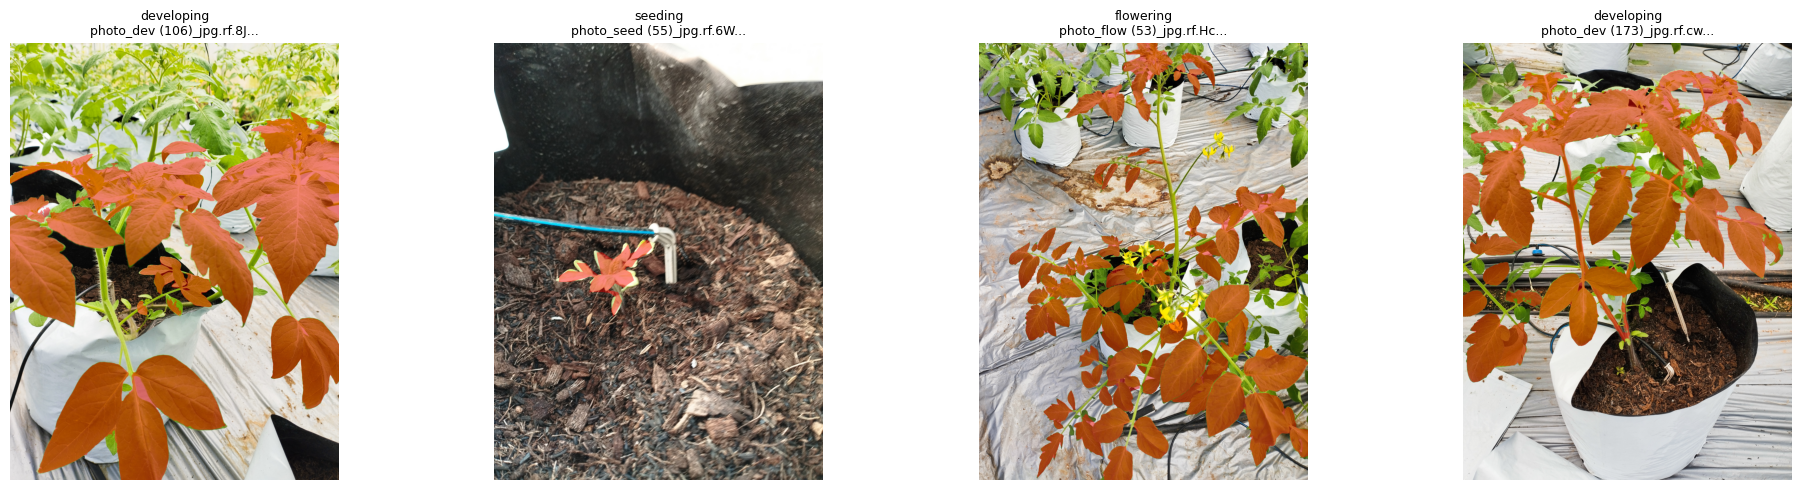

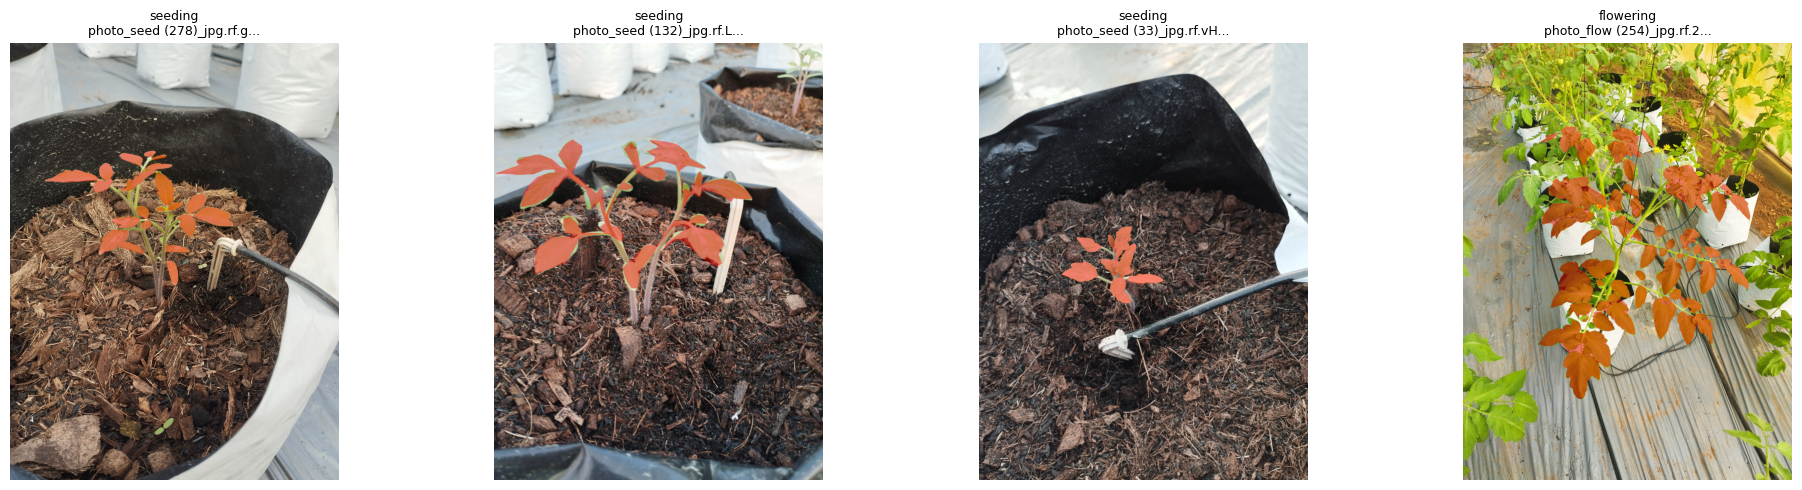

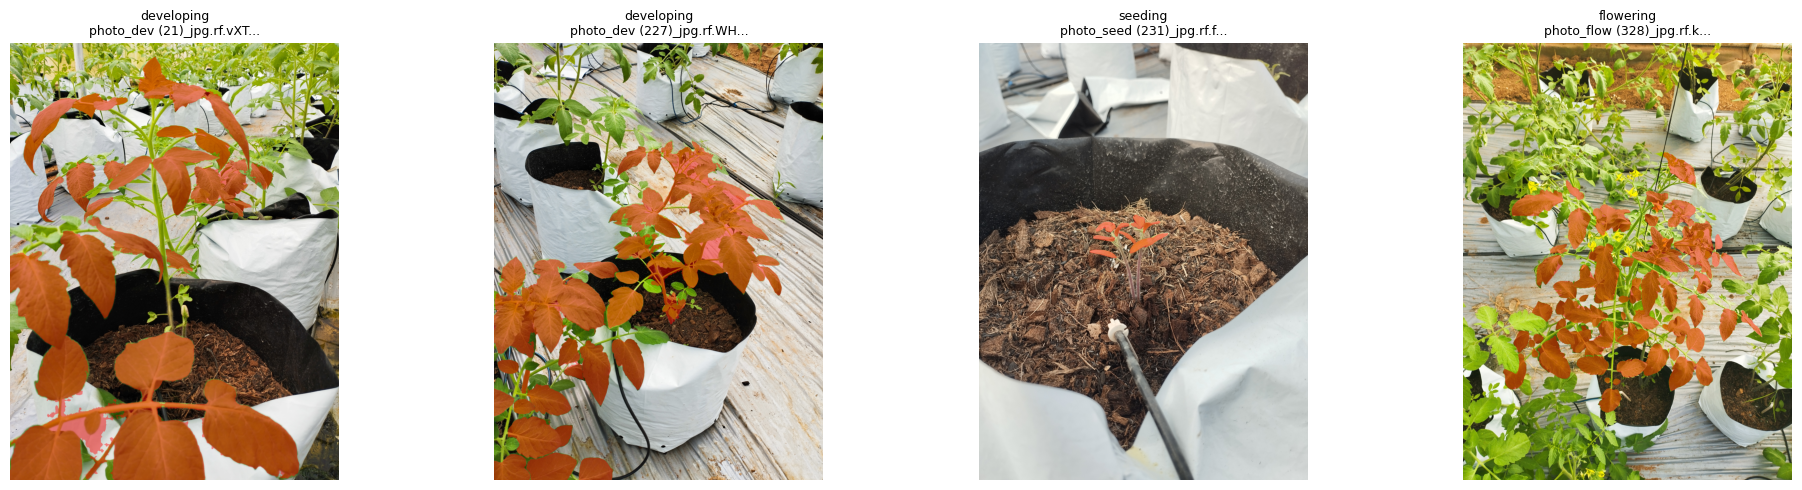

In [6]:
def show_mask_overlays(split, n=4, alpha=0.45):
    df = pd.read_csv(PROCESSED_DIR / split / "stage_mapping.csv")
    sample = df.sample(n=min(n, len(df)), random_state=SEED)

    fig, axes = plt.subplots(1, len(sample), figsize=(5 * len(sample), 5))
    if len(sample) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, sample.iterrows()):
        img = cv2.imread(str(PROCESSED_DIR / split / "images" / row["filename"]))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(str(PROCESSED_DIR / split / "masks" / row["mask_filename"]), cv2.IMREAD_GRAYSCALE)

        overlay = img.copy()
        overlay[mask > 127] = [255, 0, 0]
        blended = cv2.addWeighted(overlay, alpha, img, 1 - alpha, 0)

        ax.imshow(blended)
        ax.set_title(f'{row["growth_stage"]}\n{row["filename"][:25]}...', fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_mask_overlays("train", n=4)
show_mask_overlays("valid", n=4)
show_mask_overlays("test", n=4)


**Stop here and eyeball the overlays above.** Red should trace leaf outlines cleanly, not
whole-plant blobs or empty frames, before moving on to training.

## 3. Task 3 — U-Net training pipeline (PyTorch)

- Input: 224x224x3 RGB, output: 224x224x1 binary mask logits
- Loss: BCE + Dice (combined, handles foreground/background imbalance)
- Metrics: IoU, Dice — tracked per epoch on train and validation
- Augmentation: horizontal/vertical flip + rotation, applied identically to image and mask
- Best checkpoint selected by validation Dice; final weights also saved


In [7]:
class SegmentationDataset(Dataset):
    def __init__(self, split, img_size=IMG_SIZE, augment=False):
        self.split = split
        self.img_size = img_size
        self.augment = augment
        self.df = pd.read_csv(PROCESSED_DIR / split / "stage_mapping.csv")
        self.images_dir = PROCESSED_DIR / split / "images"
        self.masks_dir = PROCESSED_DIR / split / "masks"
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __len__(self):
        return len(self.df)

    def _augment_pair(self, img, mask):
        if random.random() < 0.5:
            img = np.fliplr(img).copy()
            mask = np.fliplr(mask).copy()
        if random.random() < 0.5:
            img = np.flipud(img).copy()
            mask = np.flipud(mask).copy()
        if random.random() < 0.5:
            angle = random.choice([90, 180, 270])
            k = angle // 90
            img = np.rot90(img, k).copy()
            mask = np.rot90(mask, k).copy()
        return img, mask

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(str(self.images_dir / row["filename"]))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(str(self.masks_dir / row["mask_filename"]), cv2.IMREAD_GRAYSCALE)

        img = cv2.resize(img, (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (self.img_size, self.img_size), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.float32)

        if self.augment:
            img, mask = self._augment_pair(img, mask)

        img = img.astype(np.float32) / 255.0
        img = (img - self.mean) / self.std
        img = np.transpose(img, (2, 0, 1))  # HWC -> CHW

        img_t = torch.from_numpy(img.copy()).float()
        mask_t = torch.from_numpy(mask.copy()).float().unsqueeze(0)  # 1xHxW
        return img_t, mask_t, row["filename"], row["growth_stage"]


In [8]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """Standard encoder-decoder U-Net with skip connections (Ronneberger et al.)."""

    def __init__(self, in_channels=3, out_channels=1, base_channels=BASE_CHANNELS):
        super().__init__()
        c = base_channels
        self.enc1 = DoubleConv(in_channels, c)
        self.enc2 = DoubleConv(c, c * 2)
        self.enc3 = DoubleConv(c * 2, c * 4)
        self.enc4 = DoubleConv(c * 4, c * 8)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(c * 8, c * 16)

        self.up4 = nn.ConvTranspose2d(c * 16, c * 8, 2, stride=2)
        self.dec4 = DoubleConv(c * 16, c * 8)
        self.up3 = nn.ConvTranspose2d(c * 8, c * 4, 2, stride=2)
        self.dec3 = DoubleConv(c * 8, c * 4)
        self.up2 = nn.ConvTranspose2d(c * 4, c * 2, 2, stride=2)
        self.dec2 = DoubleConv(c * 4, c * 2)
        self.up1 = nn.ConvTranspose2d(c * 2, c, 2, stride=2)
        self.dec1 = DoubleConv(c * 2, c)

        self.out_conv = nn.Conv2d(c, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out_conv(d1)  # logits, BCEWithLogits handles sigmoid


In [9]:
def dice_coeff(probs, targets, eps=1e-6):
    probs = probs.reshape(probs.size(0), -1)
    targets = targets.reshape(targets.size(0), -1)
    intersection = (probs * targets).sum(dim=1)
    union = probs.sum(dim=1) + targets.sum(dim=1)
    dice = (2 * intersection + eps) / (union + eps)
    return dice.mean()


def iou_score(probs, targets, threshold=MASK_THRESHOLD, eps=1e-6):
    preds = (probs > threshold).float()
    preds = preds.reshape(preds.size(0), -1)
    targets = targets.reshape(targets.size(0), -1)
    intersection = (preds * targets).sum(dim=1)
    union = preds.sum(dim=1) + targets.sum(dim=1) - intersection
    iou = (intersection + eps) / (union + eps)
    return iou.mean()


class DiceBCELoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        dice_loss = 1 - dice_coeff(probs, targets)
        return self.bce_weight * bce_loss + (1 - self.bce_weight) * dice_loss


In [10]:
train_ds = SegmentationDataset("train", augment=True)
valid_ds = SegmentationDataset("valid", augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False,
                           num_workers=NUM_WORKERS, pin_memory=True)

print("train batches:", len(train_loader), "| valid batches:", len(valid_loader))


train batches: 86 | valid batches: 17


In [11]:
model = UNet(in_channels=3, out_channels=1, base_channels=BASE_CHANNELS).to(device)
criterion = DiceBCELoss(bce_weight=0.5)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=5)
scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))

n_params = sum(p.numel() for p in model.parameters())
print(f"U-Net params: {n_params/1e6:.2f}M")


U-Net params: 7.77M


C:\Users\KOSALA\AppData\Local\Temp\ipykernel_3160\2368213004.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


In [12]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None, desc="epoch"):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, total_dice, total_iou, n_batches = 0.0, 0.0, 0.0, 0

    pbar = tqdm(loader, desc=desc, leave=False)
    with torch.set_grad_enabled(is_train):
        for imgs, masks, _, _ in pbar:
            imgs, masks = imgs.to(device), masks.to(device)

            if is_train:
                optimizer.zero_grad()
                with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                    logits = model(imgs)
                    loss = criterion(logits, masks)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                    logits = model(imgs)
                    loss = criterion(logits, masks)

            probs = torch.sigmoid(logits).float()
            total_loss += loss.item()
            total_dice += dice_coeff(probs, masks).item()
            total_iou += iou_score(probs, masks).item()
            n_batches += 1

            pbar.set_postfix(loss=total_loss / n_batches, dice=total_dice / n_batches,
                              iou=total_iou / n_batches)

    return total_loss / n_batches, total_dice / n_batches, total_iou / n_batches


In [13]:
history = {"train_loss": [], "train_dice": [], "train_iou": [],
           "val_loss": [], "val_dice": [], "val_iou": []}
best_val_dice = 0.0
best_ckpt_path = CHECKPOINT_DIR / "unet_best.pth"
final_ckpt_path = CHECKPOINT_DIR / "unet_final.pth"

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss, train_dice, train_iou = run_epoch(model, train_loader, criterion, optimizer, scaler,
                                                    desc=f"epoch {epoch:03d}/{NUM_EPOCHS} [train]")
    val_loss, val_dice, val_iou = run_epoch(model, valid_loader, criterion,
                                             desc=f"epoch {epoch:03d}/{NUM_EPOCHS} [valid]")
    scheduler.step(val_dice)

    history["train_loss"].append(train_loss)
    history["train_dice"].append(train_dice)
    history["train_iou"].append(train_iou)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)
    history["val_iou"].append(val_iou)

    print(f"epoch {epoch:03d}/{NUM_EPOCHS} | "
          f"train loss {train_loss:.4f} dice {train_dice:.4f} iou {train_iou:.4f} | "
          f"val loss {val_loss:.4f} dice {val_dice:.4f} iou {val_iou:.4f}")

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        torch.save({"model_state_dict": model.state_dict(),
                    "epoch": epoch,
                    "val_dice": val_dice,
                    "base_channels": BASE_CHANNELS,
                    "img_size": IMG_SIZE}, best_ckpt_path)
        print(f"  -> new best val dice {val_dice:.4f}, checkpoint saved")

torch.save({"model_state_dict": model.state_dict(),
            "epoch": NUM_EPOCHS,
            "val_dice": history["val_dice"][-1],
            "base_channels": BASE_CHANNELS,
            "img_size": IMG_SIZE}, final_ckpt_path)
print("training complete. best val dice:", best_val_dice)


epoch 001/60 [train]:   0%|          | 0/86 [00:00<?, ?it/s]

C:\Users\KOSALA\AppData\Local\Temp\ipykernel_3160\3900265030.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


epoch 001/60 [valid]:   0%|          | 0/17 [00:00<?, ?it/s]

C:\Users\KOSALA\AppData\Local\Temp\ipykernel_3160\3900265030.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


epoch 001/60 | train loss 0.6418 dice 0.2857 iou 0.3922 | val loss 0.5877 dice 0.2630 iou 0.5721
  -> new best val dice 0.2630, checkpoint saved


...

epoch 059/60 [valid]:   0%|          | 0/17 [00:00<?, ?it/s]

epoch 059/60 | train loss 0.1582 dice 0.8022 iou 0.7245 | val loss 0.1444 dice 0.8126 iou 0.7276


epoch 060/60 [train]:   0%|          | 0/86 [00:00<?, ?it/s]

epoch 060/60 [valid]:   0%|          | 0/17 [00:00<?, ?it/s]

epoch 060/60 | train loss 0.1569 dice 0.8032 iou 0.7258 | val loss 0.1474 dice 0.8099 iou 0.7229
training complete. best val dice: 0.8131775750833399


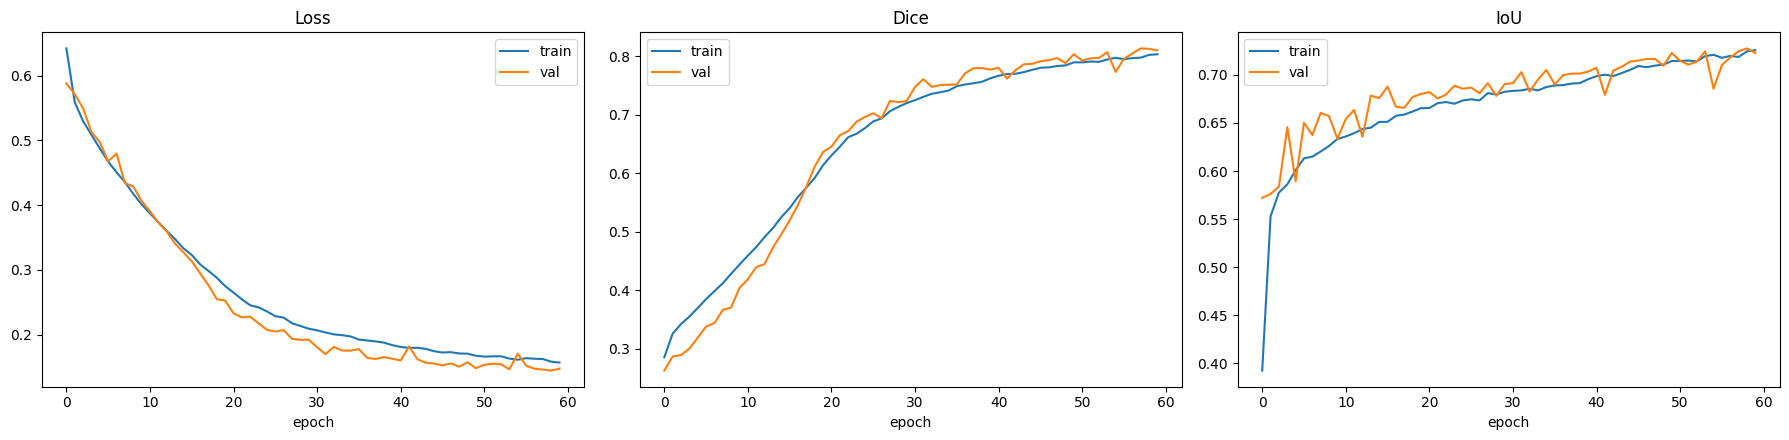

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, key, title in zip(axes, ["loss", "dice", "iou"], ["Loss", "Dice", "IoU"]):
    ax.plot(history[f"train_{key}"], label="train")
    ax.plot(history[f"val_{key}"], label="val")
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150)
plt.show()


## 4. Task 4 — Evaluation on the held-out test set

Loads the best checkpoint (by validation Dice), reports overall IoU/Dice, breaks results
down by growth stage using the stage-mapping CSV, and saves qualitative examples.


In [15]:
test_ds = SegmentationDataset("test", augment=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

eval_model = UNet(in_channels=3, out_channels=1, base_channels=BASE_CHANNELS).to(device)
ckpt = torch.load(best_ckpt_path, map_location=device)
eval_model.load_state_dict(ckpt["model_state_dict"])
eval_model.eval()
print(f"loaded best checkpoint from epoch {ckpt['epoch']}, val dice {ckpt['val_dice']:.4f}")


loaded best checkpoint from epoch 58, val dice 0.8132


In [16]:
@torch.no_grad()
def evaluate_test_set(model, loader):
    per_image_rows = []
    for imgs, masks, filenames, stages in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        logits = model(imgs)
        probs = torch.sigmoid(logits)

        for i in range(imgs.size(0)):
            p = probs[i:i+1]
            m = masks[i:i+1]
            per_image_rows.append({
                "filename": filenames[i],
                "growth_stage": stages[i],
                "dice": dice_coeff(p, m).item(),
                "iou": iou_score(p, m).item(),
            })
    return pd.DataFrame(per_image_rows)

test_results_df = evaluate_test_set(eval_model, test_loader)

overall_iou = test_results_df["iou"].mean()
overall_dice = test_results_df["dice"].mean()
print(f"Overall test IoU:  {overall_iou:.4f}")
print(f"Overall test Dice: {overall_dice:.4f}")

test_results_df.to_csv(OUTPUT_DIR / "test_set_per_image_scores.csv", index=False)


Overall test IoU:  0.6650
Overall test Dice: 0.7572


In [17]:
stage_breakdown = test_results_df.groupby("growth_stage")[["iou", "dice"]].agg(["mean", "std", "count"])
print(stage_breakdown)
stage_breakdown.to_csv(OUTPUT_DIR / "test_scores_by_stage.csv")


                   iou                      dice                
                  mean       std count      mean       std count
growth_stage                                                    
developing    0.686763  0.168574    41  0.773577  0.152345    41
flowering     0.631274  0.119107    60  0.728866  0.104836    60
fruiting      0.518619  0.200431    21  0.625009  0.211916    21
seeding       0.775595  0.091137    38  0.857499  0.067730    38


### Qualitative examples (image / ground truth / prediction)

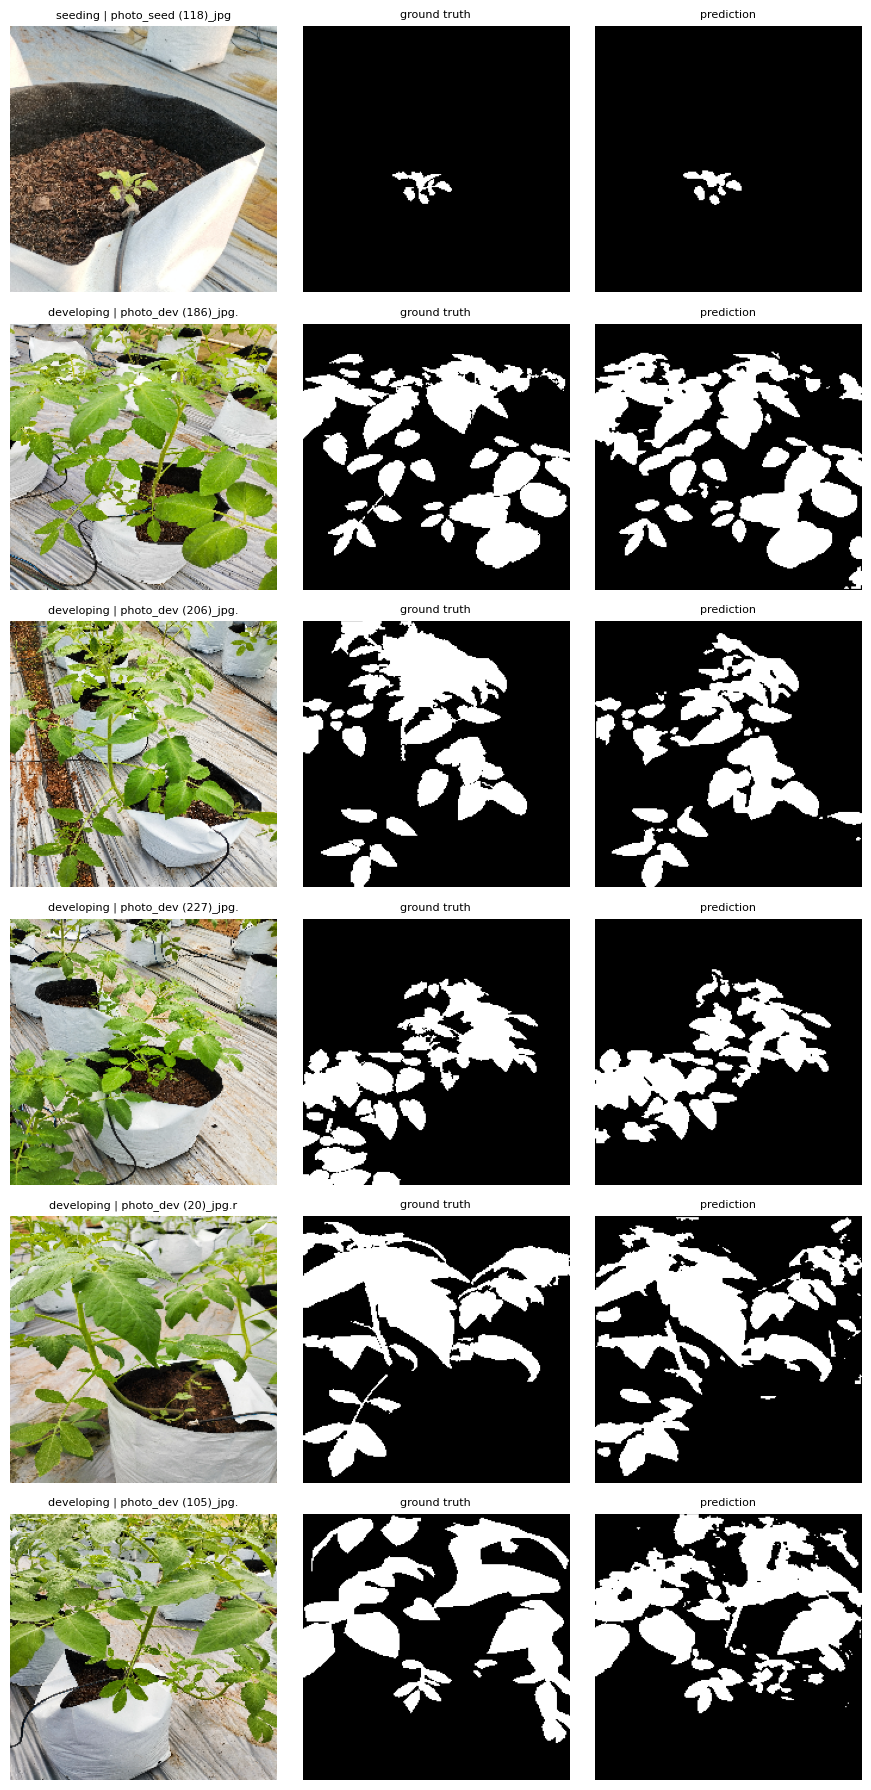

saved to d:\Reasearch\Unet\outputs\qualitative_examples\test_examples.png


In [18]:
@torch.no_grad()
def save_qualitative_examples(model, ds, n=6, threshold=MASK_THRESHOLD):
    indices = random.sample(range(len(ds)), min(n, len(ds)))
    fig, axes = plt.subplots(len(indices), 3, figsize=(9, 3 * len(indices)))
    if len(indices) == 1:
        axes = axes.reshape(1, 3)

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    for row_idx, idx in enumerate(indices):
        img_t, mask_t, filename, stage = ds[idx]
        logits = model(img_t.unsqueeze(0).to(device))
        pred = (torch.sigmoid(logits) > threshold).float().cpu().squeeze().numpy()

        img_np = img_t.numpy().transpose(1, 2, 0)
        img_np = (img_np * std + mean).clip(0, 1)
        gt_np = mask_t.squeeze().numpy()

        axes[row_idx, 0].imshow(img_np)
        axes[row_idx, 0].set_title(f"{stage} | {filename[:20]}", fontsize=8)
        axes[row_idx, 1].imshow(gt_np, cmap="gray")
        axes[row_idx, 1].set_title("ground truth", fontsize=8)
        axes[row_idx, 2].imshow(pred, cmap="gray")
        axes[row_idx, 2].set_title("prediction", fontsize=8)
        for c in range(3):
            axes[row_idx, c].axis("off")

    plt.tight_layout()
    save_path = OUTPUT_DIR / "qualitative_examples" / "test_examples.png"
    plt.savefig(save_path, dpi=150)
    plt.show()
    print("saved to", save_path)

save_qualitative_examples(eval_model, test_ds, n=6)


## 5. Task 5 — LPF (Leaf Pixel Fraction) extraction

Runs inference on any image and computes:

`LPF = (predicted leaf pixels) / (total pixels)`

This uses the trained U-Net at inference time, so it works on images without ground-truth
masks too. By default this runs over the merged `processed/{train,valid,test}/images`
folders built in Task 2, i.e. every image in `tomato final dataset` (all of which turned out
to have COCO entries — see Task 1 note on the "~63% unannotated" figure referring to a
larger pool outside this folder, if that's still needed let me know the path and I'll point
this at it too).


In [19]:
@torch.no_grad()
def compute_lpf(model, image_path, img_size=IMG_SIZE, threshold=MASK_THRESHOLD):
    """Run U-Net inference on a single image and return the leaf pixel fraction."""
    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_LINEAR)

    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    img_norm = (img_resized.astype(np.float32) / 255.0 - mean) / std
    img_t = torch.from_numpy(np.transpose(img_norm, (2, 0, 1))).unsqueeze(0).float().to(device)

    logits = model(img_t)
    probs = torch.sigmoid(logits)
    pred_mask = (probs > threshold).float().cpu().squeeze().numpy()

    lpf = pred_mask.sum() / pred_mask.size
    return float(lpf), pred_mask


In [20]:
def extract_lpf_for_dataset(model, splits=SPLITS):
    rows = []
    for split in splits:
        images_dir = PROCESSED_DIR / split / "images"
        df = pd.read_csv(PROCESSED_DIR / split / "stage_mapping.csv")
        for _, row in df.iterrows():
            image_path = images_dir / row["filename"]
            lpf, _ = compute_lpf(model, image_path)
            rows.append({
                "filename": row["filename"],
                "growth_stage": row["growth_stage"],
                "split": split,
                "LPF": lpf,
            })
        print(f"{split}: processed {len(df)} images")
    return pd.DataFrame(rows)

lpf_df = extract_lpf_for_dataset(eval_model)
lpf_df.to_csv(OUTPUT_DIR / "lpf_results.csv", index=False)
print(lpf_df.groupby("growth_stage")["LPF"].describe())
lpf_df.head()


train: processed 687 images
valid: processed 135 images
test: processed 160 images
              count      mean       std       min       25%       50%  \
growth_stage                                                            
developing    203.0  0.241552  0.078227  0.027802  0.195711  0.239039   
flowering     300.0  0.192747  0.060122  0.079161  0.146868  0.186603   
fruiting      101.0  0.144342  0.041788  0.001614  0.115713  0.138273   
seeding       378.0  0.031004  0.019768  0.005062  0.017249  0.025670   

                   75%       max  
growth_stage                      
developing    0.291225  0.439234  
flowering     0.230897  0.397939  
fruiting      0.168288  0.253288  
seeding       0.038485  0.163026  


,filename,growth_stage,split,LPF
0,photo_fruit (1)_jpg.rf.IK4YW0Dk5Tw1GLB3w25p.jpg,fruiting,train,0.172373
1,photo_fruit (113)_jpg.rf.Hv5h6Bgvq7CWh2JBC8db.jpg,fruiting,train,0.156250
2,photo_fruit (115)_jpg.rf.VMUlW3waKkfWFUIF0BhQ.jpg,fruiting,train,0.138273
3,photo_fruit (117)_jpg.rf.TLqo8JGyLmZ69BebTaYc.jpg,fruiting,train,0.162568
4,photo_fruit (118)_jpg.rf.AokYHcJKYJTqFpWcgFtl.jpg,fruiting,train,0.233976


### Using `compute_lpf` on new/unannotated images

`compute_lpf(eval_model, Path("path/to/any_image.jpg"))` works on any RGB image, including
ones outside this dataset entirely (e.g. the broader raw image pool for the ResNet50 branch)
 — no ground-truth mask required. Point `extract_lpf_for_dataset` at another image directory
by adjusting the loop above if/when that full pool needs LPF values too.


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support

@torch.no_grad()
def compute_confusion_matrix(model, loader, threshold=MASK_THRESHOLD):
    all_preds = []
    all_targets = []
    for imgs, masks, _, _ in loader:
        imgs = imgs.to(device)
        logits = model(imgs)
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float().cpu().numpy().astype(np.uint8)
        targets = masks.numpy().astype(np.uint8)

        all_preds.append(preds.reshape(-1))
        all_targets.append(targets.reshape(-1))

    all_preds = np.concatenate(all_preds)
    all_targets = np.concatenate(all_targets)
    return all_targets, all_preds

y_true, y_pred = compute_confusion_matrix(eval_model, test_loader)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
cm_norm = confusion_matrix(y_true, y_pred, labels=[0, 1], normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["background", "leaf"]).plot(
    ax=axes[0], cmap="Blues", values_format=",d")
axes[0].set_title("pixel-level confusion matrix (counts)")
ConfusionMatrixDisplay(cm_norm, display_labels=["background", "leaf"]).plot(
    ax=axes[1], cmap="Blues", values_format=".3f")
axes[1].set_title("normalized (row = true label)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=[0, 1], zero_division=0)
for i, name in enumerate(["background", "leaf"]):
    print(f"{name:10s} precision={precision[i]:.4f} recall={recall[i]:.4f} f1={f1[i]:.4f} support={support[i]}")

pixel_accuracy = (y_true == y_pred).mean()
print(f"\noverall pixel accuracy: {pixel_accuracy:.4f}")
